# 03 — scanpy QC → Pan-human Azimuth → confidence

Paper pipeline for PHA as an alternative annotation: starting from raw counts, remove low-quality
cells with scanpy, run PHA on the cells that pass, and report PHA's per-cell confidence.

QC filters (each recorded as its own column so the funnel is reportable):
- `qc_low_genes`: fewer than 200 detected genes
- `qc_high_mt`: > 10% mitochondrial counts (the lab's own threshold)
- `qc_mad_outlier`: > 5 MADs from the median on log total counts or log detected genes
- `qc_doublet`: scrublet doublet call, run per patient

**Input caveat:** the current lab files are already QC-filtered (and glioma is subsampled to 200
cells/class), so few cells are expected to be removed. Pointing `config.DATASETS` at unfiltered
matrices is all that's needed to run this on truly raw data.

Outputs → `results/qc_pha/`: `qc_pha_<dataset>_predictions.csv` (PHA + QC columns),
`qc_pha_<dataset>_embed.npy`, `qc_funnel.csv`, `confidence_by_cluster.csv`, figures.

In [1]:
import os, sys
from pathlib import Path

# Run from the repo root (found via config.py) so relative paths are stable
_root = Path.cwd()
while not (_root / "config.py").exists():
    _root = _root.parent
os.chdir(_root)
sys.path.insert(0, str(_root))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

'3'

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

from config import DATASETS, RESULTS_DIR, load_counts_adata
from pha_utils import run_pha

QC_DIR = RESULTS_DIR / "qc_pha"
QC_DIR.mkdir(parents=True, exist_ok=True)

MIN_GENES, MAX_PCT_MT, N_MADS = 200, 10.0, 5
QC_FLAGS = ["qc_low_genes", "qc_high_mt", "qc_mad_outlier", "qc_doublet"]
CONF_THRESHOLDS = [0.5, 0.75, 0.9]


def patient_col(obs):
    return "patient_id" if "patient_id" in obs else "patient"


def mad_outlier(x, n_mads):
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    return np.abs(x - med) > n_mads * 1.4826 * mad

## 1. QC

In [3]:
def run_qc(name):
    a = load_counts_adata(name)
    a.var["mt"] = a.var_names.str.upper().str.startswith("MT-")
    sc.pp.calculate_qc_metrics(a, qc_vars=["mt"], percent_top=None, log1p=True, inplace=True)

    a.obs["qc_low_genes"] = a.obs["n_genes_by_counts"] < MIN_GENES
    a.obs["qc_high_mt"] = a.obs["pct_counts_mt"] > MAX_PCT_MT
    a.obs["qc_mad_outlier"] = (mad_outlier(a.obs["log1p_total_counts"].values, N_MADS)
                               | mad_outlier(a.obs["log1p_n_genes_by_counts"].values, N_MADS))
    # scrublet normalises internally; run per patient so doublet simulation stays within a sample
    sc.pp.scrublet(a, batch_key=patient_col(a.obs), random_state=0)
    a.obs["qc_doublet"] = a.obs["predicted_doublet"].astype(bool)
    a.obs["qc_pass"] = ~a.obs[QC_FLAGS].any(axis=1)
    return a


qc = {name: run_qc(name) for name in DATASETS}

/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


In [4]:
funnel = pd.DataFrame({
    name: {"cells_in": a.n_obs,
           **{f"flagged_{f.removeprefix('qc_')}": int(a.obs[f].sum()) for f in QC_FLAGS},
           "removed": int((~a.obs["qc_pass"]).sum()),
           "kept": int(a.obs["qc_pass"].sum()),
           "kept_%": round(100 * a.obs["qc_pass"].mean(), 1),
           "has_mt_genes": bool(a.var["mt"].any())}
    for name, a in qc.items()}).T
funnel.index.name = "dataset"
funnel.to_csv(QC_DIR / "qc_funnel.csv")
funnel

,cells_in,flagged_low_genes,flagged_high_mt,flagged_mad_outlier,flagged_doublet,removed,kept,kept_%,has_mt_genes
dataset,,,,,,,,,
glioma,2609,0,0,0,55,55,2554,97.9,True
Brain_normal,2773,0,0,0,15,15,2758,99.5,True
Liver_normal,2806,0,0,0,9,9,2797,99.7,True
Lymph_node_normal,2357,0,0,0,10,10,2347,99.6,True
lymphoid,7173,0,0,0,74,74,7099,99.0,True
myeloid,6218,0,0,0,37,37,6181,99.4,True


Flags overlap, so the `flagged_*` columns can sum to more than `removed`.
Removed cells per manual cluster (does QC hit some labels disproportionately?):

In [5]:
removed_by_cluster = pd.concat([
    a.obs.groupby("true_label", observed=True)["qc_pass"]
     .agg(n="size", removed_pct=lambda s: round(100 * (~s).mean(), 1))
     .assign(dataset=name).reset_index()
    for name, a in qc.items()])
removed_by_cluster[removed_by_cluster["removed_pct"] > 0].sort_values("removed_pct", ascending=False)

,true_label,n,removed_pct,dataset
1,cDC1,93,4.3,myeloid
11,Pericyte,200,3.5,glioma
0,AC-like,200,3.0,glioma
1,Astrocyte,200,2.5,glioma
4,Endothelial,200,2.5,glioma
8,OPC,200,2.5,glioma
9,OPC-like,200,2.5,glioma
3,macrophage_C3,342,2.3,myeloid
10,monocyte_AREG_EREG,136,2.2,myeloid
6,CD8_T_cell_proliferating,89,2.2,lymphoid


## 2. PHA on QC-passing cells

In [6]:
QC_OBS_COLS = ["n_genes_by_counts", "total_counts", "pct_counts_mt", "doublet_score", *QC_FLAGS]

run_info, preds = [], {}
for name, a in qc.items():
    print(f"\n===== {name} =====")
    kept = a[a.obs["qc_pass"].values].copy()
    meta, emb, info = run_pha(kept)
    # cells_meta keeps obs columns, but make sure the QC columns travel with the predictions
    for c in QC_OBS_COLS:
        meta[c] = kept.obs[c].values
    meta.to_csv(QC_DIR / f"qc_pha_{name}_predictions.csv")
    np.save(QC_DIR / f"qc_pha_{name}_embed.npy", emb)
    preds[name] = meta
    run_info.append({"dataset": name, **info})

run_info = pd.DataFrame(run_info).set_index("dataset")
run_info.to_csv(QC_DIR / "qc_pha_run_summary.csv")
run_info


===== glioma =====


/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/site-packages/panhumanpy/ANNotate.py:1402: UserWarning: Ensure that the features metadata is indexed with gene names.
  warnings.warn(


Integer counts detected by panhumanpy.ANNotate : True
Log-normalization performed by panhumanpy.ANNotate: True
To override log-normalization, set normalization_override=False


Query object:
    Total number of cells: 2554
    Total number of features: 27102
    Overlap w. feature reference: 4625 (~91%)

Splitting query data into 1 evaluation batch(es) of up to 
8192 cells.

Interpreting label predictions for consistent granularity at broad, medium, fine level(s).

Running model:


I0000 00:00:1793219631.993207  413399 service.cc:146] XLA service 0x70fde40337b0 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793219631.993244  413399 service.cc:154]   StreamExecutor device (0): Host, Default Version


...

168/194 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

183/194 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

191/194 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


,n_cells,n_query_genes,panel_genes,panel_overlap,panel_overlap_pct,unassigned_pct,inconsistent_hierarchy_pct,median_final_conf,seconds
dataset,,,,,,,,,
glioma,2554,27102,5055,4625,91.5,0.00,28.27,0.830,9.8
Brain_normal,2758,14814,5055,3963,78.4,0.87,12.29,0.990,10.2
Liver_normal,2797,14095,5055,3753,74.2,0.00,5.72,0.997,11.7
Lymph_node_normal,2347,13717,5055,3664,72.5,0.00,14.27,0.946,8.9
lymphoid,7099,13993,5055,3793,75.0,0.08,11.52,0.938,21.0
myeloid,6181,14395,5055,3919,77.5,0.00,11.66,0.957,18.7


Sanity check: on pre-filtered input, kept cells should get the same labels as in `01` (PHA
normalises each cell independently, so removing other cells shouldn't change a cell's call).

In [7]:
for name, meta in preds.items():
    old = pd.read_csv(RESULTS_DIR / f"pha_{name}_predictions.csv", index_col=0).loc[meta.index]
    same = (old["final_level_labels"].values == meta["final_level_labels"].values).mean()
    dconf = np.abs(old["final_level_confidence"].values - meta["final_level_confidence"].values).max()
    print(f"{name:18s} same final label: {100 * same:6.2f}% | max |Δconf|: {dconf:.2e}")

glioma             same final label: 100.00% | max |Δconf|: 1.36e-06
Brain_normal       same final label: 100.00% | max |Δconf|: 9.96e-07
Liver_normal       same final label: 100.00% | max |Δconf|: 1.07e-06
Lymph_node_normal  same final label: 100.00% | max |Δconf|: 9.73e-07
lymphoid           same final label: 100.00% | max |Δconf|: 1.55e-06
myeloid            same final label: 100.00% | max |Δconf|: 1.34e-06


## 3. Confidence

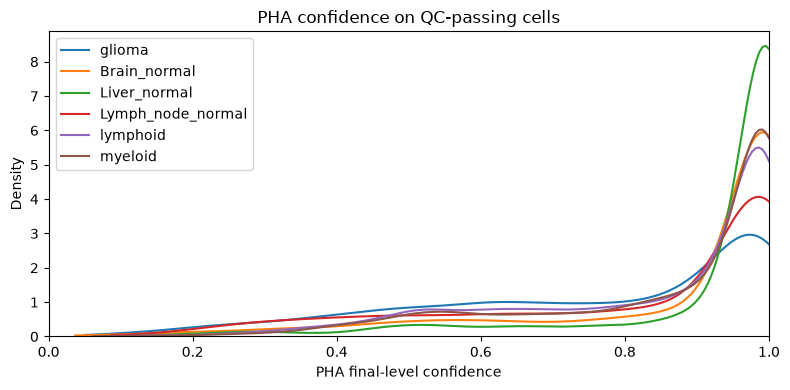

In [8]:
conf = pd.concat([m[["dataset", "true_label", "final_level_labels", "final_level_confidence"]]
                  for m in preds.values()])

fig, ax = plt.subplots(figsize=(8, 4))
for name in DATASETS:
    sns.kdeplot(conf.loc[conf["dataset"] == name, "final_level_confidence"], ax=ax, label=name,
                clip=(0, 1), cut=0)
ax.set_xlabel("PHA final-level confidence"); ax.set_xlim(0, 1)
ax.legend(); ax.set_title("PHA confidence on QC-passing cells")
plt.tight_layout(); plt.savefig(QC_DIR / "confidence_by_dataset.png", dpi=150); plt.show()

In [9]:
def conf_table(df):
    c = df["final_level_confidence"]
    return pd.Series({"n": len(c), "median_conf": c.median(),
                      **{f"conf>={t}_%": 100 * (c >= t).mean() for t in CONF_THRESHOLDS}})

conf_by_dataset = conf.groupby("dataset", sort=False).apply(conf_table, include_groups=False)
conf_by_dataset.loc["ALL"] = conf_table(conf)
conf_by_dataset.round(3).to_csv(QC_DIR / "confidence_by_dataset.csv")
conf_by_dataset.round(3)

,n,median_conf,conf>=0.5_%,conf>=0.75_%,conf>=0.9_%
dataset,,,,,
glioma,2554.0,0.830,81.519,57.557,41.425
Brain_normal,2758.0,0.990,90.682,79.405,69.942
Liver_normal,2797.0,0.997,95.030,87.272,80.872
Lymph_node_normal,2347.0,0.946,84.278,68.257,55.944
lymphoid,7099.0,0.938,91.421,71.475,56.543
myeloid,6181.0,0.957,92.331,75.279,60.605
ALL,23736.0,0.959,90.226,73.433,60.339


In [10]:
conf_by_cluster = conf.groupby(["dataset", "true_label"], sort=False).apply(conf_table, include_groups=False).round(3)
conf_by_cluster.to_csv(QC_DIR / "confidence_by_cluster.csv")
pd.set_option("display.max_rows", 200)
conf_by_cluster

n  \
dataset           true_label                                               
glioma            CD4/CD8                                          196.0   
                  Pericyte                                         193.0   
                  Endothelial                                      195.0   
                  TAM-MG                                           197.0   
                  TAM-BDM                                          200.0   
                  Oligodendrocyte                                  196.0   
                  MES-like                                         196.0   
                  OPC-like                                         195.0   
                  DC                                                 9.0   
                  OPC                                              195.0   
                  Astrocyte                                        195.0   
                  Neuron                                           196.0   
                  AC-like                                          194.0   
                  NPC-like                                         197.0   
Brain_normal      astrocyte_fibrous_like                           145.0   
                  neuron                                           603.0   
                  smooth_muscle_cell                                21.0   
                  oligodendrocyte                                  819.0   
                  GABAergic_interneuron_SST                         55.0   
                  meningeal_fibroblast                              22.0   
                  venous_endothelial_cell                           43.0   
                  astrocyte_protoplasmic                           267.0   
                  perivascular_fibroblast                           51.0   
                  oligodendrocyte_precursor_cell                    86.0   
                  GABAergic_interneuron                            152.0   
                  capillary_endothelial_cell                       161.0   
                  arterial_endothelial_cell                        107.0   
                  pericyte                                         103.0   
                  oligodendrocyte_ISG_expressing                   123.0   
Liver_normal      hepatic_stellate_cell_ACTA2_high                 200.0   
                  hepatocyte                                       907.0   
                  hepatic_stellate_cell_HGF_high                   385.0   
                  cholangiocyte                                    152.0   
                  hepatic_stellate_cell_ACTA2_high_collagen_high    92.0   
                  pericyte                                          88.0   
                  liver_pericentral_capillary_endothelial_cell     672.0   
                  liver_periportal_capillary_endothelial_cell      190.0   
                  venous_endothelial_cell                           45.0   
                  endothelial_cell_proliferating                    27.0   
                  arterial_endothelial_cell                         39.0   
Lymph_node_normal follicular_dendritic_cell                        264.0   
                  venous_endothelial_cell                          167.0   
                  LN_fibroblast_collagen_high                      537.0   
                  pericyte                                          87.0   
                  arterial_endothelial_cell                         56.0   
                  lymphatic_endothelial_cell                        91.0   
                  capillary_endothelial_cell                       205.0   
                  LN_stroma_cell                                   663.0   
                  LN_stroma_cell_CHI3L1                            204.0   
                  smooth_muscle_cell                                50.0   
                  adipocyte                                         23.0   
lymphoid          plasma_cell_proliferating

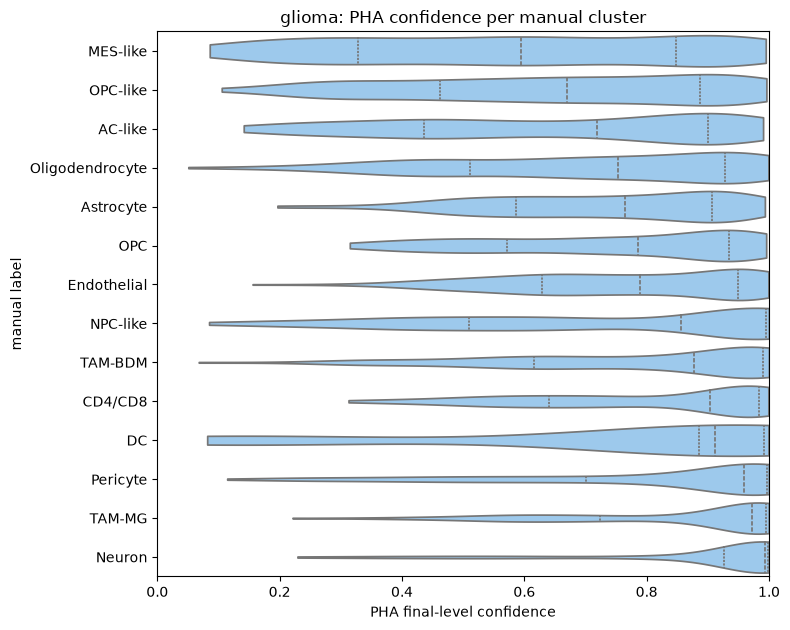

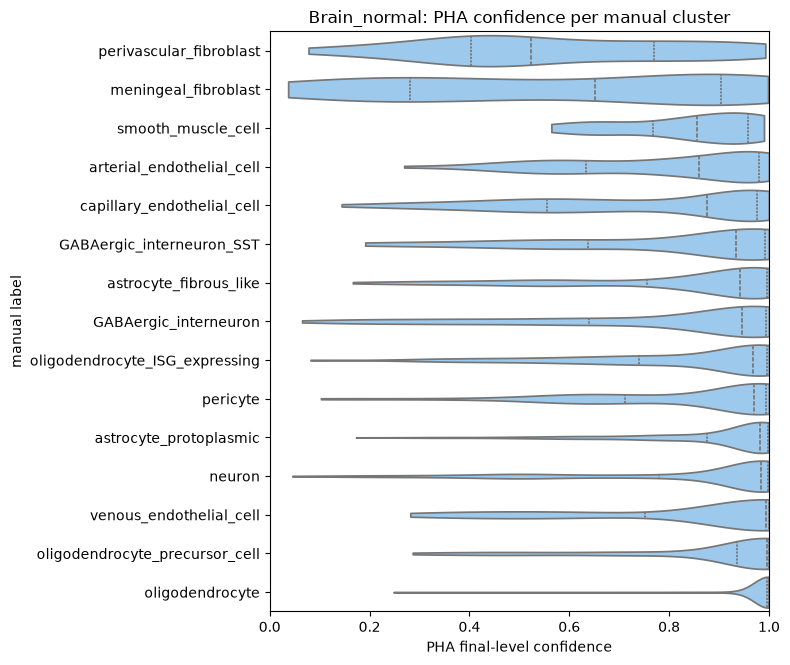

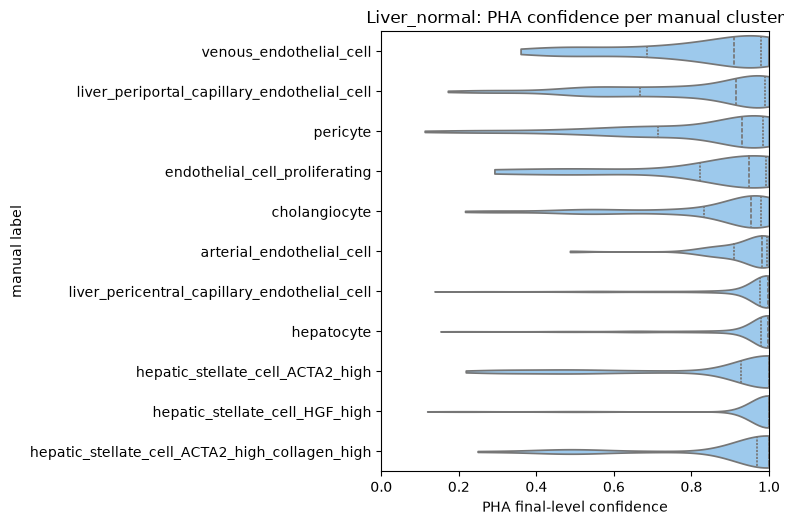

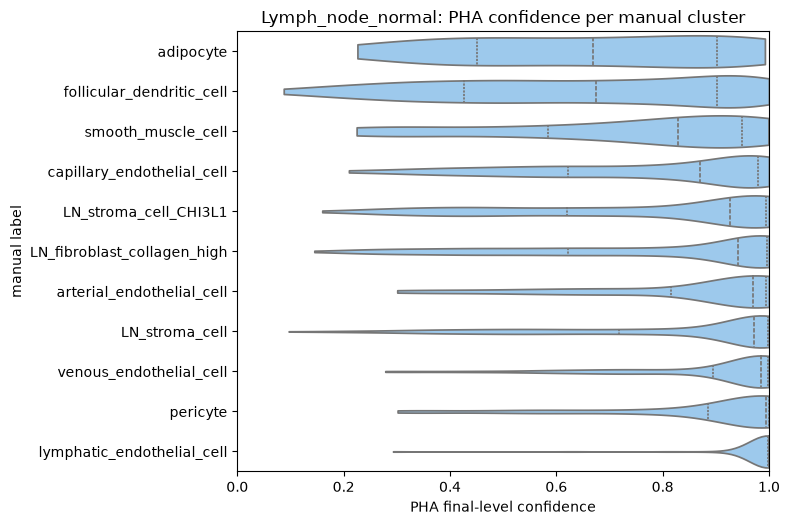

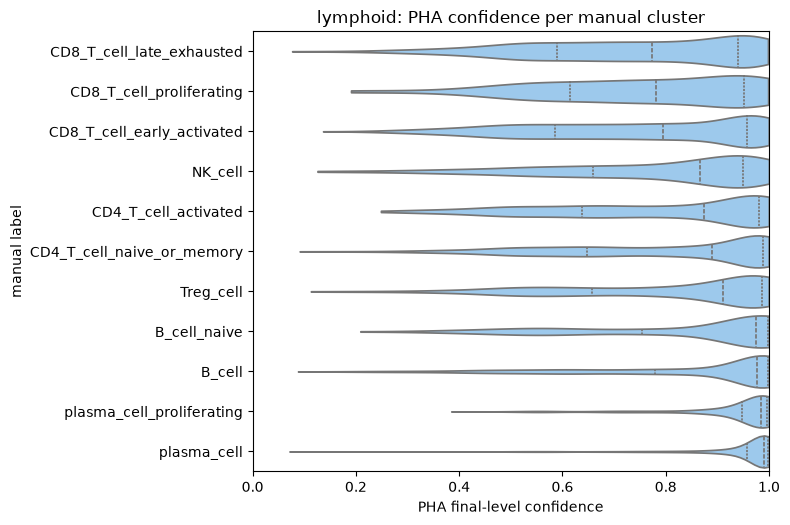

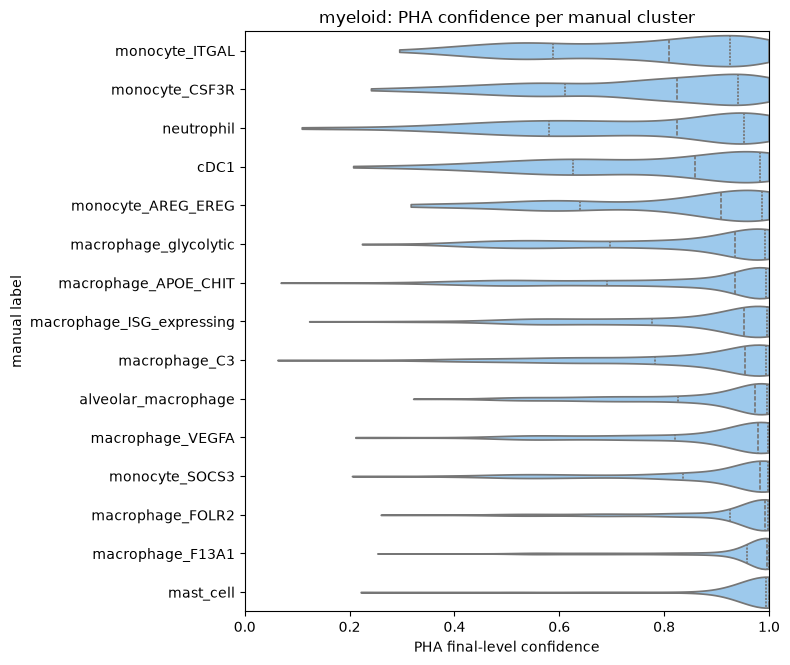

In [11]:
for name in DATASETS:
    d = conf[conf["dataset"] == name]
    order = d.groupby("true_label")["final_level_confidence"].median().sort_values().index
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(order) + 1.5))
    sns.violinplot(d, y="true_label", x="final_level_confidence", order=order, cut=0,
                   inner="quartile", density_norm="width", color="#90caf9", ax=ax)
    ax.set_xlim(0, 1); ax.set_xlabel("PHA final-level confidence"); ax.set_ylabel("manual label")
    ax.set_title(f"{name}: PHA confidence per manual cluster")
    plt.tight_layout(); plt.savefig(QC_DIR / f"confidence_violin_{name}.png", dpi=150); plt.show()